# Convergence study of the cohesive zone on a mode I DCB

The `'SB_TSL'` connection of [`MultiDomain`](../multidomain_overview.rst) resolves the progressive delamination with a Ritz basis over a *cohesive domain* of length $L_{tsl}$ and a Gauss-Legendre rule over it (see [Cohesive zone model](../cohesive_zone.rst)). This notebook studies how many terms and integration points this domain needs, and how long it must be, on a double cantilever beam (DCB). It gives the rules implemented in [`tsl_resolution`, `tsl_margin` and `tsl_discretization`](../multidomain_connections.rst).

**Reference DCB.** The specimen of Tijs et al. (2022) with $a_0 = 48$ mm and the length $L = 100$ mm of their finite element model: width 25 mm, arms of 15 unidirectional plies of 0.14 mm of AS4D/PEKK-FC ($h = 2.1$ mm), $E_1 = 133.15$ GPa, $E_2 = 10.95$ GPa (averages of the tensile and compressive moduli of their Table 1), $\nu_{12} = 0.316$, $G_{12} = 5.19$ GPa, $G_{Ic} = 1.12$ N/mm and $\tau_o = 87$ MPa. Two penalty stiffnesses of the interface are used:

- case A: $k_o = 10^5$ N/mm$^3$, the value of the validation notebooks;
- case B: $k_o = 2 \times 10^5$ N/mm$^3$.

The model, `dcb_utils.solve_dcb` with `conn_method='penalty'`: CLPT arms, far end clamped, arm tips opened to $\pm\delta/2$ by prescribed displacements, a cohesive domain of length $L_{tsl}$ ahead of the initial crack front followed by a perfect bond (`'SB'`), the load being the reaction of the prescribed displacement. The opening goes up to $\delta = 8$ mm in 38 increments: 23 equal increments up to 5 mm and increments of 0.2 mm after it.

**Stored results.** The 42 runs of the study take about 15 h of CPU time (computed below from the stored run times). They were computed by the script `dcb_mode_I_convergence_study.py` of this folder and collected in `results/dcb_mode_I_convergence_study.json`, which this notebook loads. To compute them again, from the root of the repository:

    python notebooks/dcb_mode_I_convergence_study.py run --jobs 8
    python notebooks/dcb_mode_I_convergence_study.py collect --json notebooks/results/dcb_mode_I_convergence_study.json

**References**

- B. H. A. H. Tijs, S. Abdel-Monsef, J. Renart, A. Turon and C. Bisagni, *Characterization and analysis of the interlaminar behavior of thermoplastic composites considering fiber bridging and R-curve effects*, Composites Part A 162 (2022) 107101, https://doi.org/10.1016/j.compositesa.2022.107101.
- A. Turon, C. G. Dávila, P. P. Camanho and J. Costa, *An engineering solution for mesh size effects in the simulation of delamination using cohesive zone models*, Engineering Fracture Mechanics 74(10) (2007) 1665-1682, https://doi.org/10.1016/j.engfracmech.2006.08.025.
- M. F. Kanninen, *An augmented double cantilever beam model for studying crack propagation and arrest*, International Journal of Fracture 9 (1973) 83-92, https://doi.org/10.1007/BF00035958.
- G. Alfano and M. A. Crisfield, *Finite element interface models for the delamination analysis of laminated composites: mechanical and computational issues*, International Journal for Numerical Methods in Engineering 50(7) (2001) 1701-1736, https://doi.org/10.1002/nme.93.

In [1]:
%matplotlib inline
import json
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import dcb_utils as du

with open('results/dcb_mode_I_convergence_study.json') as fid:
    study = json.load(fid)
runs = study['runs']
DCB = study['reference_dcb']
K_O = study['k_o']
REF = study['ref']
print('reference discretisation:', REF)
print(f"{len(runs)} runs, CPU time {sum(r['cpu_min'] for r in runs.values())/60:.1f} h, "
      f"wall time {sum(r['wall_min'] for r in runs.values())/60:.1f} h")

def md_table(header, rows):
    """Markdown table from a header and rows of already formatted cells"""
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    lines += ['| ' + ' | '.join(str(c) for c in r) + ' |' for r in rows]
    return Markdown('\n'.join(lines))


reference discretisation: {'L_tsl': 24.0, 'm_tsl': 25, 'n_tsl': 10, 'm': 8, 'n': 8, 'nx': 180, 'ny': 30, 'dw': 0.2}
42 runs, CPU time 14.7 h, wall time 11.8 h


## Lengths that the cohesive domain must resolve

Ahead of the process zone the opening $w^t - w^b$ of two arms connected by an elastic foundation of stiffness $k_o$ decays as $e^{-\lambda x}$ (beams on an elastic foundation, Kanninen 1973), with

$$\lambda = \left(\frac{k_o}{2 D_{11}}\right)^{1/4}$$

where $D_{11}$ is the bending stiffness of one arm per unit width. The cohesive zone, where the traction softens, has the length estimated with Rice's model (Turon et al. 2007), $l_{cz} = 0.88\,E_2 G_{Ic}/\tau_o^2$. The terms along $x$ of the cohesive domain are counted per decay length, $m_{tsl}/(\lambda L_{tsl})$, and the Gauss points per cohesive zone length, $n_x\,l_{cz}/L_{tsl}$.

In [2]:
D11 = du.D11(DCB)
lcz = 0.88*DCB['E2']*DCB['G1c']/DCB['tau_o']**2
lam = {c: (k/(2*D11))**0.25 for c, k in K_O.items()}
print(f'D11 = {D11:.0f} N mm, l_cz = {lcz:.2f} mm')
for c in K_O:
    print(f"case {c}: k_o = {K_O[c]:.0e} N/mm3, lambda = {lam[c]:.3f} 1/mm, "
          f"lambda L_tsl = {lam[c]*REF['L_tsl']:.1f} decay lengths over L_tsl = {REF['L_tsl']:g} mm")
for nx in (60, 120, 180):
    print(f"n_x = {nx}: {nx*lcz/REF['L_tsl']:.1f} points per l_cz")

D11 = 103609 N mm, l_cz = 1.43 mm
case A: k_o = 1e+05 N/mm3, lambda = 0.833 1/mm, lambda L_tsl = 20.0 decay lengths over L_tsl = 24 mm
case B: k_o = 2e+05 N/mm3, lambda = 0.991 1/mm, lambda L_tsl = 23.8 decay lengths over L_tsl = 24 mm
n_x = 60: 3.6 points per l_cz
n_x = 120: 7.1 points per l_cz
n_x = 180: 10.7 points per l_cz


## Metrics

For each run:

- the peak load $P_{max}$, the opening at the peak $\delta(P_{max})$ and the loads at $\delta = 6$, 7 and 8 mm;
- $e_P$, the largest difference of the load to that of the finest run of the same case ($m_{tsl} = 30$, $n_x = 180$) over the common openings, relative to its peak load; a run that stopped early is evaluated up to its last opening;
- $e_{eq} = \max |P_{traction}/P - 1|$, the largest relative difference between the reaction at the loaded edge and the area integral of the normal traction of the cohesive domain; both are equal by equilibrium of the loaded arm when the cohesive domain carries the whole load, so $e_{eq}$ grows when the basis does not represent the tractions or when the tractions ahead of the process zone reach the perfect bond;
- the coefficient of variation of the load drop per increment after the peak, $CV = \mathrm{std}(\Delta P)/|\mathrm{mean}(\Delta P)|$, small for a smooth softening and large for a staircase or sawtooth response;
- the number of bisected increments, of Newton-Raphson iterations and the wall time. The wall times were measured with eight runs at a time on eight cores, one thread each: they indicate the relative cost.

In [3]:
def e_P(tag):
    r = runs[tag]
    f = runs[tag[0] + '_m30_nx180']
    w, P = np.array(r['delta']), np.array(r['P'])
    wf, Pf = np.array(f['delta']), np.array(f['P'])
    err = [abs(p - Pf[np.isclose(wf, x)][0]) for x, p in zip(w, P) if np.isclose(wf, x).any()]
    return 100*max(err)/max(Pf)


fmt = lambda v, f='.2f': '-' if v is None else format(v, f)


def row(tag):
    r = runs[tag]
    end = f" (stops at {r['w_end']:.1f})" if r['aborted'] else ''
    return [fmt(r['Pmax']), fmt(r['w_Pmax'], '.1f'), fmt(r['P6']), fmt(r['P7']), fmt(r['P8']),
            f'{e_P(tag):.2f}', f"{100*r['max_rel_P_traction']:.3f}", fmt(r['cv']),
            r['bisections'], r['iters'], f"{r['wall_min']:.1f}{end}"]


HEAD = ['$P_{max}$ (N)', '$\\delta(P_{max})$ (mm)', '$P(6)$', '$P(7)$', '$P(8)$', '$e_P$ (%)',
        '$e_{eq}$ (%)', 'CV', 'bisections', 'iterations', 'wall time (min)']

## Terms $m_{tsl}$ and Gauss points $n_x$ along $x$ of the cohesive domain

Full grid $m_{tsl} \in \{10, 15, 20, 25, 30\} \times n_x \in \{60, 120, 180\}$ with $L_{tsl} = 24$ mm and the other parameters of the reference discretisation, $n_{tsl} = 10$, $n_y = 30$ and $8 \times 8$ terms in the other domains. Loads in N.

In [4]:
rows = []
for c in K_O:
    for m in (10, 15, 20, 25, 30):
        for nx in (60, 120, 180):
            tag = f'{c}_m{m}_nx{nx}'
            rows.append([c, m, nx, f'{m/(lam[c]*REF["L_tsl"]):.2f}'] + row(tag))
display(md_table(['case', '$m_{tsl}$', '$n_x$', '$m_{tsl}/\\lambda L_{tsl}$'] + HEAD, rows))

| case | $m_{tsl}$ | $n_x$ | $m_{tsl}/\lambda L_{tsl}$ | $P_{max}$ (N) | $\delta(P_{max})$ (mm) | $P(6)$ | $P(7)$ | $P(8)$ | $e_P$ (%) | $e_{eq}$ (%) | CV | bisections | iterations | wall time (min) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 10 | 60 | 0.50 | 168.36 | 6.2 | 166.88 | - | - | 5.09 | 17.834 | - | 7 | 80 | 9.2 (stops at 6.2) |
| A | 10 | 120 | 0.50 | 168.22 | 6.2 | 166.88 | 154.38 | - | 5.01 | 31.129 | 2.16 | 11 | 340 | 19.0 (stops at 7.2) |
| A | 10 | 180 | 0.50 | 168.25 | 6.2 | 166.88 | 154.38 | 141.13 | 5.03 | 44.420 | 1.98 | 3 | 323 | 9.9 |
| A | 15 | 60 | 0.75 | 166.43 | 5.6 | 162.85 | 150.95 | 139.52 | 1.16 | 0.272 | 0.63 | 3 | 283 | 10.3 |
| A | 15 | 120 | 0.75 | 166.23 | 5.6 | 162.52 | 151.68 | 139.73 | 0.77 | 0.264 | 0.56 | 0 | 145 | 4.7 |
| A | 15 | 180 | 0.75 | 166.19 | 5.6 | 162.53 | 151.71 | 139.95 | 0.71 | 0.265 | 0.51 | 0 | 139 | 4.7 |
| A | 20 | 60 | 1.00 | 166.36 | 5.6 | 162.74 | 150.30 | 140.96 | 0.64 | 0.088 | 0.42 | 3 | 317 | 19.8 |
| A | 20 | 120 | 1.00 | 166.16 | 5.6 | 162.57 | 150.63 | 140.89 | 0.21 | 0.088 | 0.26 | 0 | 143 | 8.0 |
| A | 20 | 180 | 1.00 | 166.12 | 5.6 | 162.71 | 150.66 | 140.93 | 0.08 | 0.088 | 0.24 | 0 | 136 | 9.2 |
| A | 25 | 60 | 1.25 | 166.35 | 5.6 | 162.68 | 150.21 | 140.78 | 0.60 | 0.089 | 0.40 | 3 | 384 | 40.3 |
| A | 25 | 120 | 1.25 | 166.14 | 5.6 | 162.51 | 150.51 | 140.75 | 0.17 | 0.089 | 0.24 | 0 | 135 | 13.2 |
| A | 25 | 180 | 1.25 | 166.10 | 5.6 | 162.65 | 150.54 | 140.78 | 0.02 | 0.089 | 0.23 | 0 | 139 | 14.4 |
| A | 30 | 60 | 1.50 | 166.34 | 5.6 | 162.67 | 150.21 | 140.78 | 0.60 | 0.089 | 0.40 | 3 | 358 | 58.2 |
| A | 30 | 120 | 1.50 | 166.14 | 5.6 | 162.51 | 150.49 | 140.77 | 0.17 | 0.089 | 0.24 | 0 | 135 | 21.2 |
| A | 30 | 180 | 1.50 | 166.10 | 5.6 | 162.65 | 150.53 | 140.81 | 0.00 | 0.088 | 0.24 | 0 | 140 | 22.2 |
| B | 10 | 60 | 0.42 | 169.42 | 6.4 | 166.62 | 154.12 | - | 7.23 | 18.392 | 2.69 | 7 | 140 | 10.7 (stops at 7.4) |
| B | 10 | 120 | 0.42 | 169.24 | 6.4 | 166.41 | 153.75 | 140.40 | 7.12 | 31.392 | 2.14 | 1 | 229 | 5.2 |
| B | 10 | 180 | 0.42 | 169.16 | 6.4 | 166.40 | 153.69 | 140.42 | 7.08 | 31.413 | 2.14 | 0 | 158 | 3.3 |
| B | 15 | 60 | 0.63 | 166.29 | 5.8 | 162.00 | 151.84 | - | 1.02 | 2.278 | 0.70 | 8 | 222 | 22.3 (stops at 7.8) |
| B | 15 | 120 | 0.63 | 166.36 | 5.8 | 162.54 | 152.12 | 139.47 | 1.00 | 2.283 | 0.59 | 0 | 141 | 4.5 |
| B | 15 | 180 | 0.63 | 166.39 | 5.8 | 162.57 | 152.08 | 139.44 | 1.04 | 2.281 | 0.57 | 0 | 145 | 5.0 |
| B | 20 | 60 | 0.84 | 166.07 | 5.6 | 162.27 | 150.90 | 142.31 | 0.92 | 0.032 | 0.51 | 2 | 238 | 14.3 |
| B | 20 | 120 | 0.84 | 166.24 | 5.6 | 162.67 | 150.58 | 141.10 | 0.21 | 0.032 | 0.25 | 0 | 159 | 10.9 |
| B | 20 | 180 | 0.84 | 166.20 | 5.6 | 162.70 | 150.65 | 140.94 | 0.14 | 0.032 | 0.25 | 0 | 143 | 9.5 |
| B | 25 | 60 | 1.05 | 166.02 | 5.6 | 162.11 | 150.72 | 142.14 | 0.82 | 0.006 | 0.53 | 1 | 189 | 17.9 |
| B | 25 | 120 | 1.05 | 166.19 | 5.6 | 162.52 | 150.42 | 140.90 | 0.10 | 0.004 | 0.23 | 0 | 141 | 14.4 |
| B | 25 | 180 | 1.05 | 166.15 | 5.6 | 162.56 | 150.49 | 140.75 | 0.02 | 0.004 | 0.23 | 0 | 140 | 14.6 |
| B | 30 | 60 | 1.26 | 166.02 | 5.6 | 162.11 | 150.69 | 142.13 | 0.82 | 0.004 | 0.53 | 2 | 239 | 38.3 |
| B | 30 | 120 | 1.26 | 166.19 | 5.6 | 162.53 | 150.41 | 140.99 | 0.13 | 0.004 | 0.24 | 0 | 137 | 22.2 |
| B | 30 | 180 | 1.26 | 166.14 | 5.6 | 162.57 | 150.49 | 140.77 | 0.00 | 0.004 | 0.23 | 0 | 141 | 23.2 |

## Other parameters, varied one at a time

From the reference discretisation $L_{tsl} = 24$ mm, $m_{tsl} = 25$, $n_x = 180$: the terms along $y$ of the cohesive domain ($n_{tsl} = 10 \to 15$), the Gauss points along $y$ ($n_y = 30 \to 60$), the terms of the other domains ($m = n = 8 \to 12$), the increment after $\delta = 5$ mm (halved, 53 openings instead of 38) and the length of the cohesive domain ($L_{tsl} = 24 \to 17$ mm).

In [5]:
names = {'m25_nx180': 'reference', 'n15': '$n_{tsl}$ = 15', 'ny60': '$n_y$ = 60', 'mn12': '$m = n$ = 12',
         'w01': 'increment 0.1 mm', 'L17_m25_nx180': '$L_{tsl}$ = 17 mm', 'L17_m15_nx120': '$L_{tsl}$ = 17 mm, $m_{tsl}$ = 15, $n_x$ = 120'}
rows = [[c, label] + row(f'{c}_{k}') for c in K_O for k, label in names.items()]
display(md_table(['case', 'variation'] + HEAD, rows))

| case | variation | $P_{max}$ (N) | $\delta(P_{max})$ (mm) | $P(6)$ | $P(7)$ | $P(8)$ | $e_P$ (%) | $e_{eq}$ (%) | CV | bisections | iterations | wall time (min) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A | reference | 166.10 | 5.6 | 162.65 | 150.54 | 140.78 | 0.02 | 0.089 | 0.23 | 0 | 139 | 14.4 |
| A | $n_{tsl}$ = 15 | 166.10 | 5.6 | 162.64 | 150.54 | 140.77 | 0.02 | 0.089 | 0.23 | 0 | 136 | 39.4 |
| A | $n_y$ = 60 | 166.10 | 5.6 | 162.63 | 150.52 | 140.77 | 0.02 | 0.087 | 0.24 | 0 | 136 | 17.1 |
| A | $m = n$ = 12 | 166.10 | 5.6 | 162.66 | 150.54 | 140.78 | 0.02 | 0.087 | 0.24 | 0 | 134 | 18.5 |
| A | increment 0.1 mm | 166.13 | 5.7 | 162.65 | 150.54 | 140.78 | 0.02 | 0.089 | 0.15 | 0 | 184 | 19.3 |
| A | $L_{tsl}$ = 17 mm | 166.08 | 5.6 | 162.57 | 150.49 | 140.74 | 0.06 | 32.439 | 0.24 | 0 | 138 | 14.9 |
| A | $L_{tsl}$ = 17 mm, $m_{tsl}$ = 15, $n_x$ = 120 | 166.10 | 5.6 | 162.66 | 150.38 | 140.67 | 0.11 | 32.834 | 0.25 | 0 | 142 | 4.2 |
| B | reference | 166.15 | 5.6 | 162.56 | 150.49 | 140.75 | 0.02 | 0.004 | 0.23 | 0 | 140 | 14.6 |
| B | $n_{tsl}$ = 15 | 166.14 | 5.6 | 162.56 | 150.49 | 140.73 | 0.03 | 0.005 | 0.23 | 0 | 136 | 40.1 |
| B | $n_y$ = 60 | 166.14 | 5.6 | 162.55 | 150.49 | 140.75 | 0.02 | 0.004 | 0.24 | 0 | 143 | 18.5 |
| B | $m = n$ = 12 | 166.14 | 5.6 | 162.57 | 150.49 | 140.75 | 0.01 | 0.004 | 0.23 | 0 | 140 | 19.3 |
| B | increment 0.1 mm | 166.21 | 5.7 | 162.56 | 150.49 | 140.75 | 0.02 | 0.004 | 0.15 | 0 | 176 | 19.1 |
| B | $L_{tsl}$ = 17 mm | 166.15 | 5.6 | 162.60 | 150.48 | 140.78 | 0.08 | 10.219 | 0.24 | 0 | 142 | 15.2 |
| B | $L_{tsl}$ = 17 mm, $m_{tsl}$ = 15, $n_x$ = 120 | 166.12 | 5.6 | 162.63 | 150.25 | 140.64 | 0.25 | 10.959 | 0.28 | 0 | 142 | 4.4 |

## Load-opening curves

Case A: the terms $m_{tsl}$ with $n_x = 180$ (left) and the Gauss points $n_x$ with $m_{tsl} = 25$ (right), around the peak.

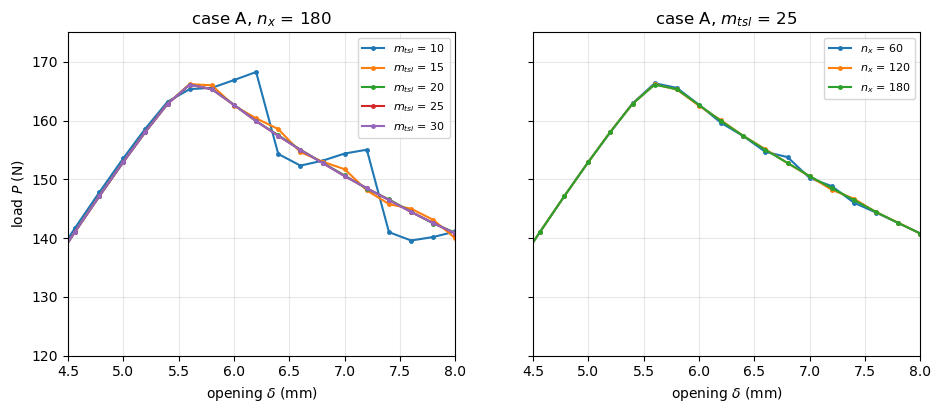

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for m in (10, 15, 20, 25, 30):
    r = runs[f'A_m{m}_nx180']
    axes[0].plot(r['delta'], r['P'], '-o', ms=2.5, label=f'$m_{{tsl}}$ = {m}')
for nx in (60, 120, 180):
    r = runs[f'A_m25_nx{nx}']
    axes[1].plot(r['delta'], r['P'], '-o', ms=2.5, label=f'$n_x$ = {nx}')
for ax in axes:
    ax.set_xlim(4.5, 8.)
    ax.set_ylim(120, 175)
    ax.set_xlabel('opening $\\delta$ (mm)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('load $P$ (N)')
axes[0].set_title('case A, $n_x$ = 180')
axes[1].set_title('case A, $m_{tsl}$ = 25')
plt.show()

## Error against the terms per decay length

When the errors $e_P$ of both cases are plotted against $m_{tsl}/(\lambda L_{tsl})$, the number of terms per decay length of the opening, they fall on one curve for a given number of points per cohesive zone length.

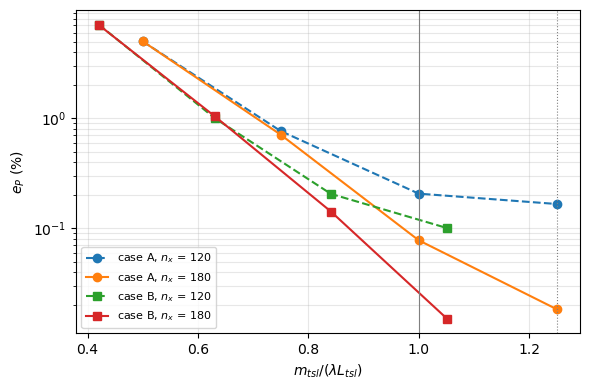

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for c, mk in (('A', 'o'), ('B', 's')):
    for nx, ls in ((120, '--'), (180, '-')):
        ms = [10, 15, 20, 25]
        ax.semilogy([m/(lam[c]*REF['L_tsl']) for m in ms], [e_P(f'{c}_m{m}_nx{nx}') for m in ms],
                    ls=ls, marker=mk, label=f'case {c}, $n_x$ = {nx}')
ax.axvline(1.0, color='0.5', lw=0.8)
ax.axvline(1.25, color='0.5', lw=0.8, ls=':')
ax.set_xlabel('$m_{tsl}/(\\lambda L_{tsl})$')
ax.set_ylabel('$e_P$ (%)')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8)
plt.show()

## Length of the cohesive domain and equilibrium

The crack growth $\Delta a$ at the last opening and the margin $3 l_{cz} + 8/\lambda$ for the process zone and the region ahead of it, where the opening decays to below $e^{-8}$ of its value, against the length of the cohesive domain, with $e_{eq}$ at the last opening.

In [8]:
rows = []
for c in K_O:
    margin = 3*lcz + 8/lam[c]
    for k in ('m25_nx180', 'L17_m25_nx180'):
        r = runs[f'{c}_{k}']
        L_tsl = REF['L_tsl'] if k == 'm25_nx180' else 17.
        growth = r['a_end'] - DCB['a0']
        rel = abs(r['P_traction'][-1]/r['P'][-1] - 1)
        rows.append([c, f'{L_tsl:g}', f'{growth:.1f}', f'{margin:.1f}', f'{growth + margin:.1f}',
                     f"{100*rel:.3f}", f"{100*r['max_rel_P_traction']:.3f}"])
display(md_table(['case', '$L_{tsl}$ (mm)', '$\\Delta a$ (mm)', '$3 l_{cz} + 8/\\lambda$ (mm)',
                  'needed (mm)', '$e_{eq}$ at the end (%)', '$e_{eq}$ max (%)'], rows))

| case | $L_{tsl}$ (mm) | $\Delta a$ (mm) | $3 l_{cz} + 8/\lambda$ (mm) | needed (mm) | $e_{eq}$ at the end (%) | $e_{eq}$ max (%) |
|---|---|---|---|---|---|---|
| A | 24 | 9.8 | 13.9 | 23.7 | 0.089 | 0.089 |
| A | 17 | 9.8 | 13.9 | 23.6 | 32.439 | 32.439 |
| B | 24 | 9.8 | 12.3 | 22.2 | 0.001 | 0.004 |
| B | 17 | 9.8 | 12.3 | 22.1 | 10.219 | 10.219 |

## Rules of the discretisation

From these results the discretisation of the cohesive domain follows the rules

$$m_{tsl} = 1.25\,\lambda L_{tsl}, \qquad n_x = 10\,\frac{L_{tsl}}{l_{cz}}, \qquad L_{tsl} \geq \Delta a + 3 l_{cz} + \frac{8}{\lambda}$$

with $m_{tsl} \leq 25$, $n_x \geq 4 m_{tsl}$ rounded up to a multiple of 10, $n_{tsl} = 10$, $n_y = 30$ and $m = n = 8$ in the other domains, implemented in [`tsl_resolution`, `tsl_margin` and `tsl_discretization`](../multidomain_connections.rst) and in `dcb_utils.discretize`, which the validation notebooks use. For the reference DCB they give:

In [9]:
for c in K_O:
    case = du.discretize(dict(DCB, k_o=K_O[c]), REF['L_tsl'])
    print(f"case {c}: m_tsl = {case['m_tsl']}, nx = {case['nx']}, "
          f"P_max of the reference run {runs[c + '_m25_nx180']['Pmax']:.2f} N "
          f"at delta = {runs[c + '_m25_nx180']['w_Pmax']:.1f} mm")

case A: m_tsl = 25, nx = 170, P_max of the reference run 166.10 N at delta = 5.6 mm
case B: m_tsl = 25, nx = 170, P_max of the reference run 166.15 N at delta = 5.6 mm


## Discussion

- **The Ritz basis of the cohesive domain sets the shape of the response after the peak.** With $m_{tsl} = 10$, about 0.4-0.5 terms per decay length, the basis cannot follow the process zone: the load overshoots the converged curve after the peak and then drops in a sawtooth ($CV$ = 2.0-2.7), $e_P$ is 5-7%, $e_{eq}$ reaches 18-44%, and three of the six runs stop before $\delta = 8$ mm when an increment does not converge after the last bisection. With $m_{tsl} = 15$ the curve is smooth ($CV$ = 0.5-0.7) but still 0.7-1.2% off. Against the terms per decay length the errors of both cases fall on one curve, below 0.1% from about one term per decay length with $n_x = 180$; the rule $m_{tsl} = 1.25\,\lambda L_{tsl}$ keeps a margin over this threshold. The Bardell functions go up to 30 terms, so a cohesive domain longer than about $30/\lambda$ is not resolved.
- **The Gauss points along $x$ set the robustness and a floor of the error.** With 3.6 points per $l_{cz}$ ($n_x = 60$) the error stays at 0.6-0.9% however many terms are used, and increments need bisection, because the crack front crosses several integration points in one increment; with 10.7 points per $l_{cz}$ ($n_x = 180$) and $m_{tsl} \geq 25$ the error is at most 0.02%, without bisection. Unlike the terms, the integration points do not change the shape of the curve.
- **The other parameters do not matter here.** More terms or points across the width and more terms in the other domains change the loads by hundredths of a percent, since the specimen is uniform across the width; halving the increment only changes where the peak is sampled. The stiffer interface of case B raises the initial stiffness slightly, but the peak and the loads after it differ from those of case A by less than 0.1%, in line with the insensitivity of the DCB to $k_o > 10^4$ N/mm$^3$ shown by Turon et al. (2007, Fig. 9).
- **The length of the cohesive domain is detected by $e_{eq}$, not by the load.** With $L_{tsl} = 24$ mm the crack growth plus the margin fits in the cohesive domain up to $\delta = 8$ mm and $e_{eq}$ stays small. With $L_{tsl} = 17$ mm the loads hardly change, but in the last openings the compressive lobe ahead of the process zone enters the perfect bond and $e_{eq}$ grows to 10-33%.
- **The sawtooth is a discrete snap-back.** With too few terms the basis cannot follow the process zone continuously, like a cohesive finite element mesh that is coarse compared with the cohesive zone (Alfano and Crisfield 2001; Turon et al. 2007): the elastic energy builds up while the crack front is held and is released when a group of integration points fails at once, which a displacement-controlled analysis crosses as a sudden load drop.